In [4]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/house_price_regression_dataset.csv")

In [5]:
from sklearn.model_selection import train_test_split
X=df[['Square_Footage','Num_Bedrooms','Num_Bathrooms','Year_Built','Lot_Size','Garage_Size','Neighborhood_Quality']]
y=df['House_Price']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
(X_test)

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
521,4012,3,1,2016,2.098092,1,5
737,2310,3,1,1988,1.369622,1,4
740,4708,1,3,1962,1.792970,1,8
660,4932,2,1,1972,4.479598,1,2
411,3646,1,1,1994,3.980987,0,9
...,...,...,...,...,...,...,...
408,3767,5,3,1981,1.520335,2,4
332,616,2,3,1965,3.461372,1,7
208,4491,4,2,1994,3.399155,0,4
613,1858,1,1,1996,4.546672,2,8


In [7]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

In [8]:
print(model.coef_)

[  199.5132451  10225.20442601  8208.43477213   993.53717098
 14885.38441545  5146.14838675   115.06859497]


In [9]:
print(model.intercept_)

-2010567.4201016547


In [12]:
y_predict = model.predict(X_test)

In [13]:

results = pd.DataFrame({
    'Actual House Price': y_test.values,
    'Predicted House Price': y_predict
})
print(results)


     Actual House Price  Predicted House Price
0          9.010005e+05           8.686871e+05
1          4.945375e+05           4.903379e+05
2          9.494042e+05           9.456671e+05
3          1.040389e+06           1.033403e+06
4          7.940100e+05           7.766988e+05
..                  ...                    ...
195        8.245296e+05           8.183308e+05
196        1.803936e+05           1.671845e+05
197        9.658167e+05           9.749354e+05
198        4.336642e+05           4.405538e+05
199        6.639050e+05           6.632887e+05

[200 rows x 2 columns]


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_predict)
mse = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predict)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 8174.583599866779
Mean Squared Error: 101434798.45037025
Root Mean Squared Error: 10071.484421393416
R2 Score: 0.9984263636832063


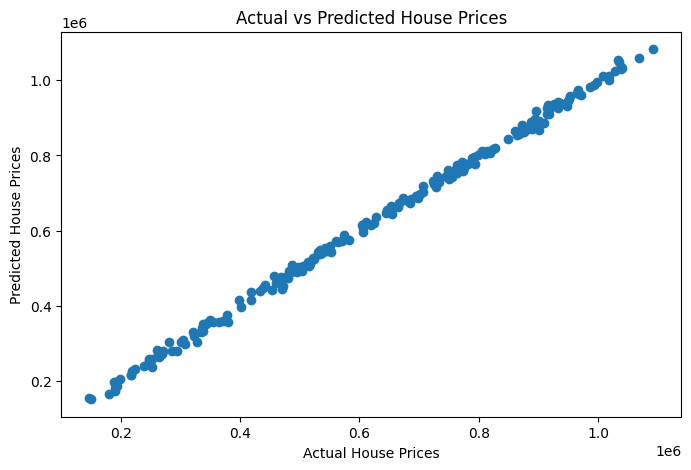

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_predict)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()